# Phase 10.2 - Validación estricta expanding + holdout final

Entrena sólo con pasado hasta una fecha de corte y evalúa el siguiente bloque; al final prueba un holdout completamente intocable.

In [1]:
from pathlib import Path
import subprocess

ROOT = Path('.')
SCRIPT = ROOT / 'phases/phase10_decision_engine/run_phase10_2_strict_expanding_holdout.py'

res = subprocess.run(['python', str(SCRIPT)], cwd=ROOT, check=True, capture_output=True, text=True)
print(res.stdout)
if res.stderr:
    print(res.stderr)


Saved summary: ./phases/phase10_decision_engine/output_phase10_2_strict_expanding_GBPUSD/GBPUSD_phase10_2_summary.json
Windows mean metrics:
{'train_rows': 12768.5, 'test_rows': 1425.0, 'phase9_thr': 0.49999999999999994, 'policy_conf_thr': 0.46666666666666673, 'policy_inf_min': 0.3, 'policy_calib_score': 1.5546015967841817, 'acc_action_3': 0.308421052631579, 'f1_macro_action_3': 0.2918973535234752, 'avg_net_return': 0.00012452245923317236, 'cum_net_return': 0.17744450440727064, 'std_net_return': 0.0034196865341150824, 'sharpe_ann': 2.8876534547407946, 'trade_rate': 0.31590643152594566, 'win_rate_trades': 0.5725506403316991}
Holdout metrics:
{'split': 'holdout_final', 'train_rows': 20355, 'test_rows': 3596, 'timestamp_test_start': '2020-09-21 03:00:00', 'timestamp_test_end': '2025-10-29 19:00:00', 'phase9_thr': 0.55, 'policy_conf_thr': 0.45, 'policy_inf_min': 0.3, 'policy_calib_score': 1.6075514568351577, 'acc_action_3': 0.32619577308120135, 'f1_macro_action_3': 0.32455052218516484, 'av

In [2]:
import json
import pandas as pd
from IPython.display import display

OUT = ROOT / 'phases/phase10_decision_engine/output_phase10_2_strict_expanding_GBPUSD'
summary = json.loads((OUT / 'GBPUSD_phase10_2_summary.json').read_text())
windows = pd.read_csv(OUT / 'GBPUSD_phase10_2_windows_metrics.csv')
holdout = pd.read_csv(OUT / 'GBPUSD_phase10_2_holdout_metrics.csv')
phase9 = pd.read_csv(OUT / 'GBPUSD_phase10_2_phase9_metrics.csv')

print('Dataset:', summary['dataset'])
print('Windows mean metrics:')
display(pd.Series(summary['windows']['mean_metrics']).to_frame('mean'))
print('Windows by split:')
display(windows)
print('Holdout final:')
display(holdout)
print('Phase9 fold stats:')
display(phase9)


Dataset: {'n_total_rows': 23967, 'n_pre_rows': 20371, 'n_holdout_rows': 3596, 'pre_date_min': '2000-05-31 10:00:00', 'pre_date_max': '2020-09-21 02:00:00', 'holdout_date_min': '2020-09-21 03:00:00', 'holdout_date_max': '2025-10-29 19:00:00'}
Windows mean metrics:


,mean
train_rows,12768.500000
test_rows,1425.000000
phase9_thr,0.500000
policy_conf_thr,0.466667
policy_inf_min,0.300000
policy_calib_score,1.554602
acc_action_3,0.308421
f1_macro_action_3,0.291897
avg_net_return,0.000125
cum_net_return,0.177445


Windows by split:


,split,train_rows,test_rows,timestamp_test_start,timestamp_test_end,phase9_thr,policy_conf_thr,policy_inf_min,policy_calib_score,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,sharpe_ann,trade_rate,win_rate_trades
0,w1,9166,1425,2009-04-06 22:00:00,2009-12-04 12:00:00,0.450,0.45,0.3,1.655577,0.350175,0.345143,0.000091,0.129732,0.003856,1.836113,0.516491,0.552989
1,w2,10607,1425,2009-12-07 20:00:00,2010-09-28 10:00:00,0.500,0.40,0.3,1.630830,0.346667,0.345641,0.000122,0.174253,0.003634,2.617194,0.480000,0.542398
2,w3,12048,1425,2010-09-30 14:00:00,2012-04-03 20:00:00,0.475,0.55,0.3,1.744437,0.191579,0.157419,0.000079,0.113110,0.001516,4.072878,0.070877,0.673267
3,w4,13489,1425,2012-04-25 01:00:00,2015-04-01 01:00:00,0.550,0.45,0.3,1.125127,0.356491,0.342009,0.000089,0.126581,0.003187,2.167572,0.319298,0.538462
4,w5,14930,1425,2015-04-03 09:00:00,2016-07-11 10:00:00,0.500,0.55,0.3,1.450126,0.241404,0.203055,0.000291,0.415108,0.004386,5.165630,0.112982,0.596273
5,w6,16371,1425,2016-07-12 06:00:00,2017-11-10 13:00:00,0.525,0.40,0.3,1.721513,0.364211,0.358116,0.000074,0.105883,0.003940,1.466534,0.395789,0.531915


Holdout final:


,split,train_rows,test_rows,timestamp_test_start,timestamp_test_end,phase9_thr,policy_conf_thr,policy_inf_min,policy_calib_score,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,sharpe_ann,trade_rate,win_rate_trades
0,holdout_final,20355,3596,2020-09-21 03:00:00,2025-10-29 19:00:00,0.55,0.45,0.3,1.607551,0.326196,0.324551,0.000163,0.58665,0.004038,3.141828,0.3604,0.54784


Phase9 fold stats:


,split,best_score,thr,score,acc,f1_macro_all,f1_macro_informative,recall_class0,mae_progress,rmse_progress,mae_progress_early
0,w1,0.375422,0.450,0.375422,0.481077,0.286788,0.161562,0.675082,0.102911,0.138104,0.081463
1,w2,0.436364,0.500,0.436364,0.390321,0.324859,0.356600,0.457746,0.074734,0.093485,0.085516
2,w3,0.453120,0.475,0.453120,0.516325,0.334891,0.251659,0.682927,0.072799,0.088050,0.079611
3,w4,0.411381,0.550,0.411381,0.518043,0.297616,0.216963,0.638965,0.076169,0.090286,0.062891
4,w5,0.436237,0.500,0.436237,0.528808,0.294711,0.239929,0.602285,0.030132,0.039965,0.027727
5,w6,0.494319,0.525,0.494319,0.750305,0.346064,0.153511,0.865679,0.061946,0.077603,0.036867
6,holdout_final,0.435103,0.550,0.435103,0.560760,0.325517,0.267001,0.698113,0.095351,0.134678,0.100308


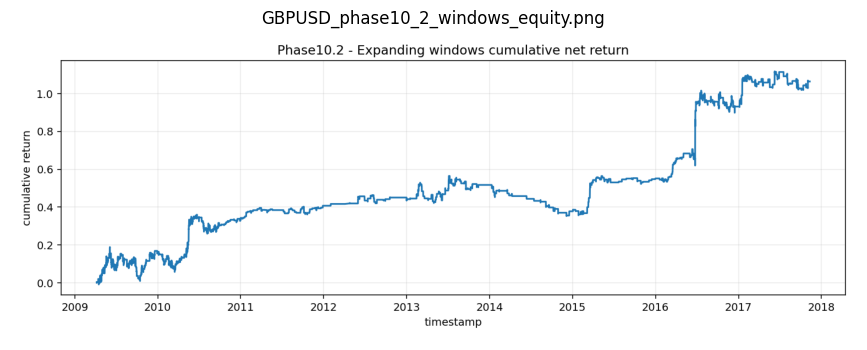

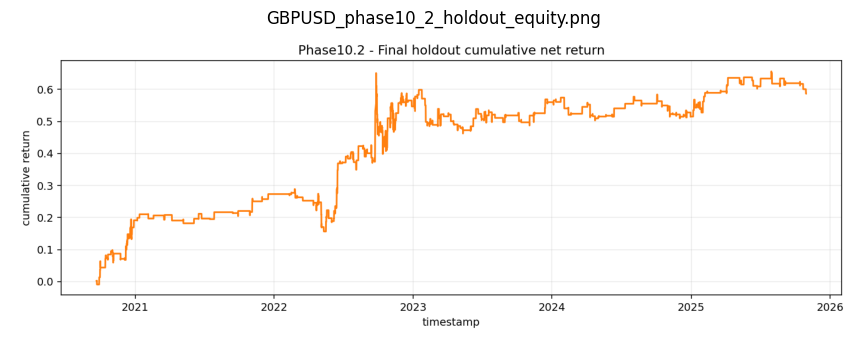

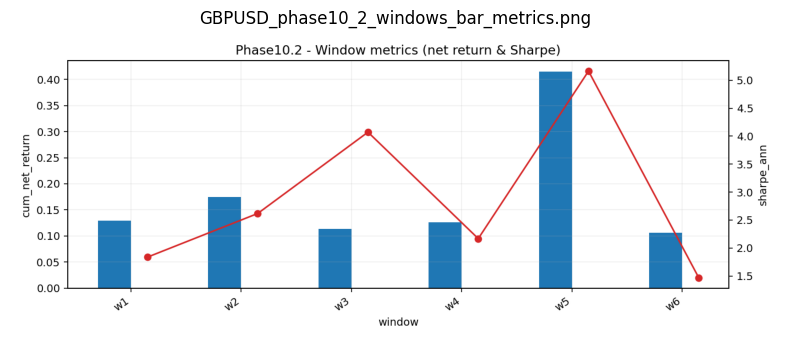

In [3]:
import matplotlib.pyplot as plt

imgs = [
    OUT / 'GBPUSD_phase10_2_windows_equity.png',
    OUT / 'GBPUSD_phase10_2_holdout_equity.png',
    OUT / 'GBPUSD_phase10_2_windows_bar_metrics.png',
]

for p in imgs:
    img = plt.imread(p)
    plt.figure(figsize=(12, 4))
    plt.imshow(img)
    plt.title(p.name)
    plt.axis('off')
    plt.show()
